# The 1644 Ming crisis: a generation of artists and scientists not trained
Does the crisis (rebellions from 1628, fall of Beijing in 1644, end of the Southern Ming in 1662) leave a hole in the cohorts born during it, which would explain a decline of cultural production one generation later? Only birth years, only culture and science, visual only.

**Territory**: individuals matched to the Ming, Later Jin, Li Zicheng (Shun), Southern Ming or Qing polity (`humans_clean_enriched_v3`), taken together. **Birth years and occupations**: `cultura_enriched_v3.2` (copy taken before the polity ingestion). **Culture / science**: one Wikidata occupation classified "Culture" or "Discovery/Science".

In [1]:
import tempfile

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.ticker import MaxNLocator
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2_before_polities.duckdb'
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'

TERRITORY_POLITIES = ['Ming Dynasty', 'Later Jin Dynasty', 'Li Zicheng', 'Southern Ming', 'Qing Dynasty']
DOMAINS = {'Culture': 'culture', 'Discovery/Science': 'science'}
BIRTH_START, BIRTH_END = 1550, 1750
BASELINE = (1580, 1610)
PEAK = (1610, 1630)
CRISIS_START, FALL_OF_BEIJING, CRISIS_END = 1628, 1644, 1662
TOP_NAMES = 12
FEMALE_QID = 'Q6581072'
COHORT_START, COHORT_END = 1590, 1690
SCHOOL_COHORT_START = 1615
PHASES = {'adult when the crisis began': SILVER, 'children at school during the crisis': ORANGE,
          'born during the crisis': RED, 'born after the crisis': BLUE}

DOMAIN_COLORS = {'culture': BLUE, 'science': GREEN}
CRISIS_BORN_COLOR = RED
CRISIS_SHADE = {'color': PALE_GREY, 'lw': 0, 'zorder': 0}

apply_style()

## External data
None. The crisis years (1628, 1644, 1662) are the only constants not read from the database.

## Load data

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql('''
    CREATE TEMP TABLE territory_individuals AS
    SELECT DISTINCT entity.qid AS qid
    FROM   (SELECT entity, unnest(polity) AS polity_match FROM polity_db.individual_enriched)
    WHERE  list_contains($names, polity_match.polity.name)
''', params={'names': TERRITORY_POLITIES})

producers = con.sql('''
    WITH person_occupation AS (
        SELECT territory_individuals.qid, unnest(individual.occupation).entity.qid AS occupation_qid
        FROM   territory_individuals
        JOIN   individual ON individual.entity.qid = territory_individuals.qid
    )
    SELECT DISTINCT person_occupation.qid,
           occupation.meta_occupation,
           individual_enriched.entity.label_en        AS name,
           individual_enriched.entity.description     AS description,
           individual_enriched.birth_date.year        AS birth_year,
           individual_enriched.birth_date.source      AS birth_source,
           len(individual.sitelink)                   AS sitelinks
    FROM   person_occupation
    JOIN   occupation          ON occupation.entity.qid = person_occupation.occupation_qid
    JOIN   individual          ON individual.entity.qid = person_occupation.qid
    JOIN   individual_enriched ON individual_enriched.entity.qid = person_occupation.qid
    WHERE  list_contains($domains, occupation.meta_occupation)
''', params={'domains': list(DOMAINS)}).pl().with_columns(pl.col('meta_occupation').replace(DOMAINS).alias('domain'))
profiles = con.sql('''
    SELECT territory_individuals.qid,
           any_value(individual.sex_or_gender = $female)                                       AS is_female,
           bool_or(occupation.meta_occupation = 'Leadership') OR any_value(len(individual.position_held) > 0) AS ever_official
    FROM   territory_individuals
    JOIN   individual ON individual.entity.qid = territory_individuals.qid
    LEFT JOIN (SELECT individual.entity.qid AS qid, unnest(individual.occupation).entity.qid AS occupation_qid FROM individual) AS person_occupation
           ON person_occupation.qid = territory_individuals.qid
    LEFT JOIN occupation ON occupation.entity.qid = person_occupation.occupation_qid
    GROUP BY territory_individuals.qid
''', params={'female': FEMALE_QID}).pl().with_columns(pl.col('ever_official').fill_null(False), pl.col('is_female').fill_null(False))
con.close()

print(f"culture or science individuals on the territory: {producers['qid'].n_unique():,}")
producers.sample(5, seed=42)

culture or science individuals on the territory: 3,642


qid,meta_occupation,name,description,birth_year,birth_source,sitelinks,domain
str,str,str,str,i64,str,i64,str
"""Q7967402""","""Discovery/Science""","""Wang Daiyu""","""Chinese scholar""",1570,"""wikidata""",6,"""science"""
"""Q10919475""","""Culture""","""Wu Songliang""","""Qing dynasty person CBDB=54727""",1766,"""wikidata""",1,"""culture"""
"""Q11098257""","""Culture""","""Li Kaixian""","""Chinese writer; CBDB ID = 1248…",1502,"""wikidata""",7,"""culture"""
"""Q45549136""","""Culture""","""Chen Quan""","""Ming dynasty person CBDB = 130…",1359,"""wikidata""",0,"""culture"""
"""Q11094797""","""Culture""","""Zhu Gengyang""","""Qing dynasty person CBDB = 743…",1848,"""wikidata""",1,"""culture"""


## Preprocessing
### Births per decade
A cohort is **born during the crisis** when its whole decade of birth falls between 1628 and 1662: the 1630s, 1640s and 1650s.

In [3]:
born = producers.filter(pl.col('birth_year').is_between(BIRTH_START, BIRTH_END - 1)).with_columns(
    (pl.col('birth_year') // 10 * 10).alias('decade')
)
print(f"rows born {BIRTH_START}-{BIRTH_END - 1}: {born.height:,}, birth year estimated: {(born['birth_source'] == 'estimated').sum():,}")

decades = pl.DataFrame({'decade': range(BIRTH_START, BIRTH_END, 10)})
births = decades.join(
    born.group_by('decade', 'domain').len().pivot(on='domain', index='decade', values='len'), on='decade', how='left'
).fill_null(0).with_columns(
    ((pl.col('decade') >= CRISIS_START) & (pl.col('decade') + 10 <= CRISIS_END)).alias('born_during_crisis')
)
births

rows born 1550-1749: 1,378, birth year estimated: 71


decade,culture,science,born_during_crisis
i64,u32,u32,bool
1550,23,14,false
1560,27,13,false
1570,37,11,false
1580,52,13,false
1590,61,13,false
…,…,…,…
1700,42,11,false
1710,39,6,false
1720,50,11,false


### Pre-crisis level and missing births
Two reference levels, births per decade averaged over: the cohorts born 1580-1609 (before the peak) and the cohorts born 1610-1629 (the peak: young adults at the fall). For the cohorts born during the crisis, the gap below the 1580-1609 level is drawn as missing births.

In [4]:
baseline = {domain: births.filter(pl.col('decade').is_between(BASELINE[0], BASELINE[1] - 1))[domain].mean() for domain in DOMAIN_COLORS}
peak = {domain: births.filter(pl.col('decade').is_between(PEAK[0], PEAK[1] - 1))[domain].mean() for domain in DOMAIN_COLORS}
missing = births.filter(pl.col('born_during_crisis')).select(
    'decade', *DOMAIN_COLORS, *[(baseline[domain] - pl.col(domain)).clip(lower_bound=0).alias(f'missing_{domain}') for domain in DOMAIN_COLORS]
)
print('1580-1609 level:', {domain: round(level, 1) for domain, level in baseline.items()})
print('1610-1629 level:', {domain: round(level, 1) for domain, level in peak.items()})
missing

1580-1609 level: {'culture': 55.0, 'science': 13.7}
1610-1629 level: {'culture': 115.5, 'science': 19.0}


decade,culture,science,missing_culture,missing_science
i64,u32,u32,f64,f64
1630,68,13,0.0,0.666667
1640,76,11,0.0,2.666667
1650,39,8,16.0,5.666667


### Five-year cohorts: training or opportunities?
Culture and science together, one row per individual. Birth years ending in 0 are removed, because many are rounded (heaping). Each cohort gets a phase from its birth year:
adult when the crisis began (born before 1615), children at school during the crisis (born 1615-1629, aged 0-13 in 1628 and 15-29 in 1644), born during the crisis (1630-1662), born after.

In [5]:
def phase(year):
    return (pl.when(year < SCHOOL_COHORT_START).then(pl.lit(list(PHASES)[0]))
            .when(year < CRISIS_START).then(pl.lit(list(PHASES)[1]))
            .when(year < CRISIS_END).then(pl.lit(list(PHASES)[2]))
            .otherwise(pl.lit(list(PHASES)[3])))


cohort_people = (
    born.unique('qid').join(profiles, on='qid', how='left')
    .filter(pl.col('birth_year').is_between(COHORT_START, COHORT_END - 1), pl.col('birth_year') % 10 != 0)
    .with_columns((pl.col('birth_year') // 5 * 5).alias('cohort'))
)
cohorts = (
    cohort_people.group_by('cohort')
    .agg(pl.len().alias('all'), (~pl.col('ever_official')).sum().alias('never_official'), pl.col('is_female').sum().alias('women'))
    .sort('cohort')
    .with_columns(phase(pl.col('cohort') + 2).alias('phase'))
)
assert cohorts['all'].sum() == cohort_people.height
print(f"individuals in the 5-year cohorts (round years removed): {cohort_people.height:,}")
cohorts

individuals in the 5-year cohorts (round years removed): 687


cohort,all,never_official,women,phase
i64,u32,u32,u32,str
1590,29,19,7,"""adult when the crisis began"""
1595,37,34,5,"""adult when the crisis began"""
1600,26,24,3,"""adult when the crisis began"""
1605,33,28,4,"""adult when the crisis began"""
1610,44,37,5,"""adult when the crisis began"""
…,…,…,…,…
1665,30,16,2,"""born after the crisis"""
1670,22,15,2,"""born after the crisis"""
1675,19,10,1,"""born after the crisis"""


## Figures
### Figure 1: Cultural producers and scientists born per decade
Red: cohorts born during the crisis. Dashed line: level of the cohorts born 1580-1609. Dotted line: level of the cohorts born 1610-1629. Hatched: births below the 1580-1609 level among the cohorts born during the crisis.

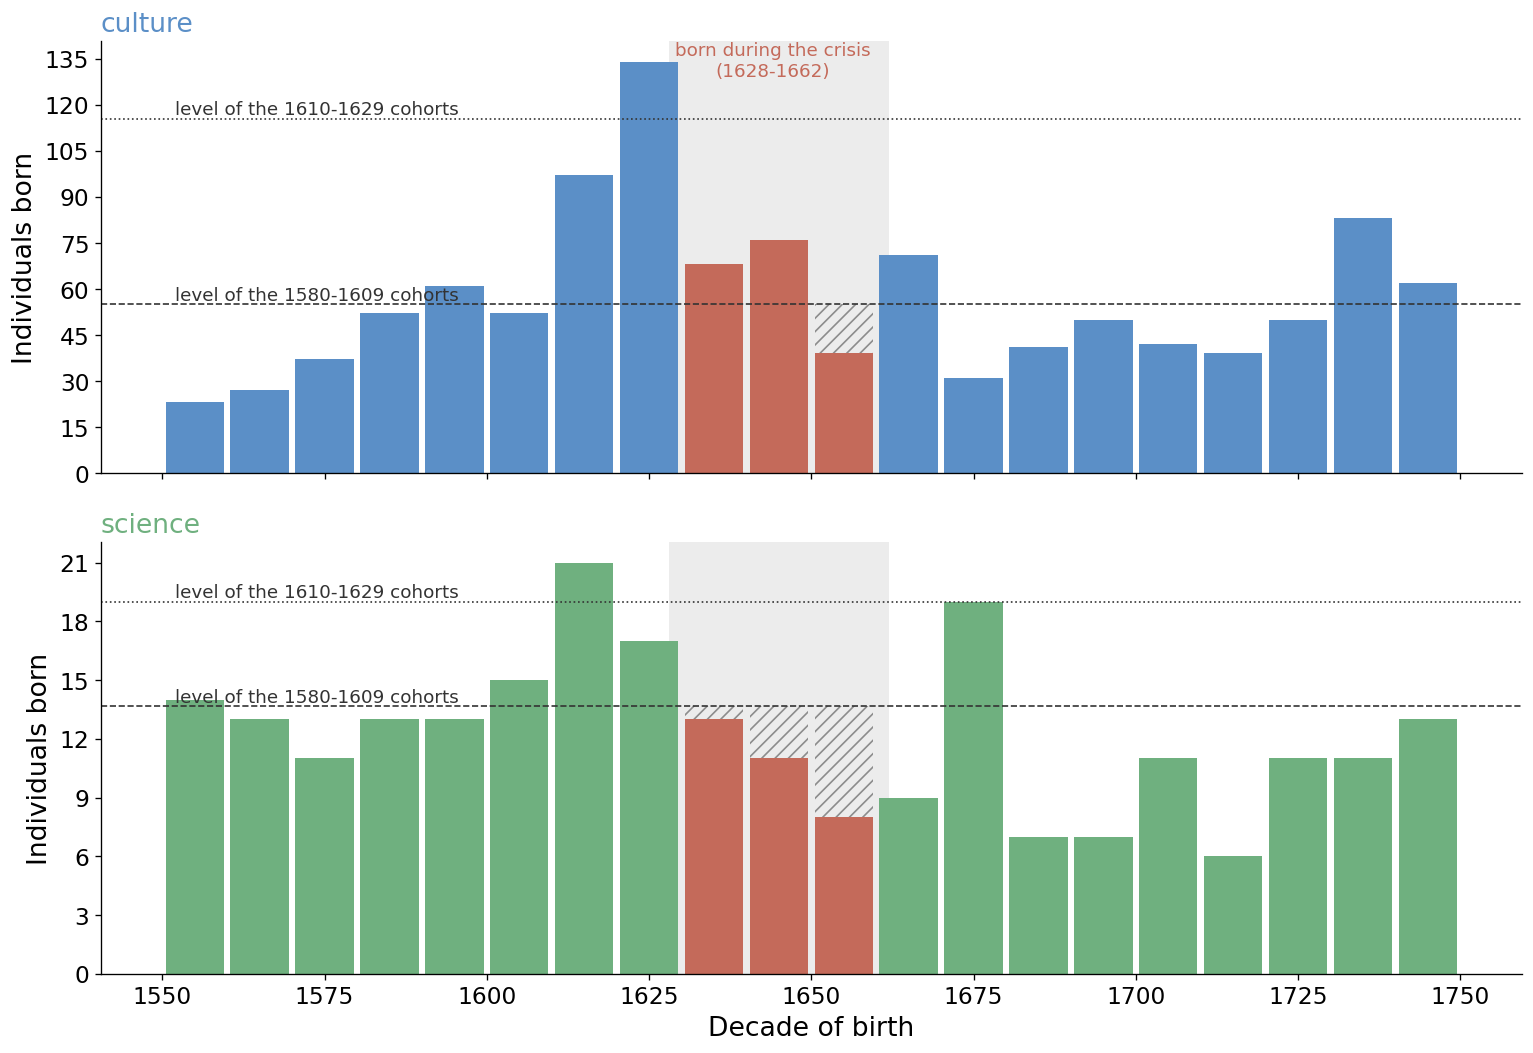

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for ax, domain in zip(axes, DOMAIN_COLORS):
    colors = [CRISIS_BORN_COLOR if crisis else DOMAIN_COLORS[domain] for crisis in births['born_during_crisis']]
    ax.axvspan(CRISIS_START, CRISIS_END, **CRISIS_SHADE)
    ax.bar(births['decade'] + 5, births[domain], width=9, color=colors)
    ax.bar(missing['decade'] + 5, missing[f'missing_{domain}'], width=9, bottom=missing[domain], color='none', edgecolor=GREY, hatch='///', lw=0)
    ax.axhline(baseline[domain], color=TEXT, ls='--', lw=1)
    ax.text(BIRTH_START + 2, baseline[domain], 'level of the 1580-1609 cohorts', va='bottom', fontsize=SMALL_LEGEND_FONTSIZE, color=TEXT)
    ax.axhline(peak[domain], color=TEXT, ls=':', lw=1)
    ax.text(BIRTH_START + 2, peak[domain], 'level of the 1610-1629 cohorts', va='bottom', fontsize=SMALL_LEGEND_FONTSIZE, color=TEXT)
    ax.set_title(domain, color=DOMAIN_COLORS[domain], loc='left')
    ax.set_ylabel('Individuals born')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].text(FALL_OF_BEIJING, 1.0, 'born during the crisis\n(1628-1662)', transform=axes[0].get_xaxis_transform(),
             ha='center', va='top', fontsize=SMALL_LEGEND_FONTSIZE, color=CRISIS_BORN_COLOR)
axes[1].set_xlabel('Decade of birth')
plt.tight_layout()
plt.show()

### Figure 2: Five-year cohorts of cultural producers and scientists, by what the crisis meant at their age
Left: all, and those who never held office or a Leadership occupation (no need of a state post). Right: women, excluded from exams and office. Top axis: age in 1644. Dashed line: level of the cohorts born 1590-1614.

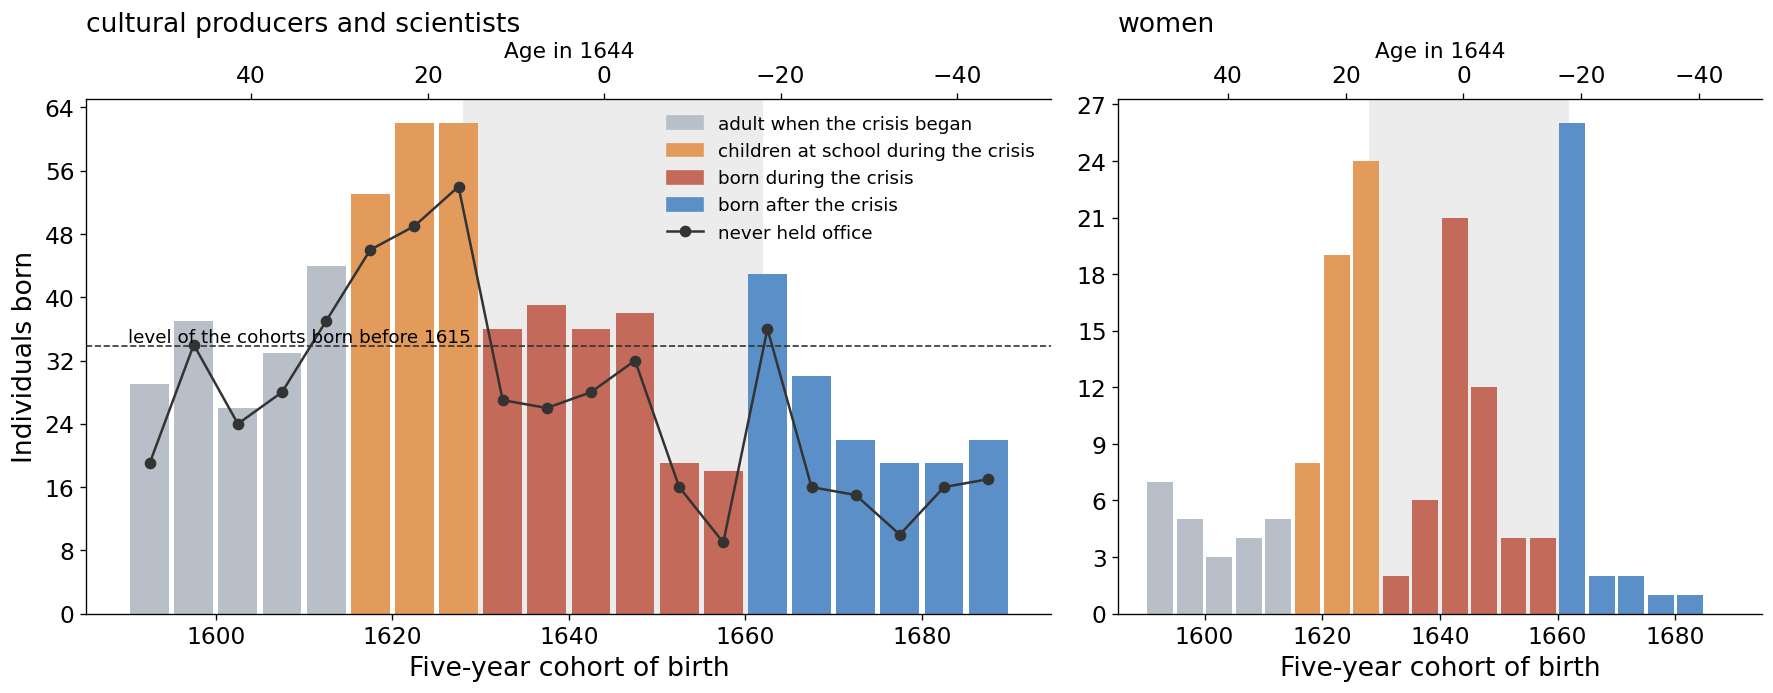

In [7]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE, gridspec_kw={'width_ratios': [3, 2]})
colors = [PHASES[name] for name in cohorts['phase']]
for ax, column, title in [(axes[0], 'all', 'cultural producers and scientists'), (axes[1], 'women', 'women')]:
    ax.axvspan(CRISIS_START, CRISIS_END, **CRISIS_SHADE)
    ax.bar(cohorts['cohort'] + 2.5, cohorts[column], width=4.4, color=colors)
    ax.set_title(title, loc='left')
    ax.set_xlabel('Five-year cohort of birth')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    top = ax.secondary_xaxis('top', functions=(lambda x: FALL_OF_BEIJING - x, lambda age: FALL_OF_BEIJING - age))
    top.set_xlabel('Age in 1644', fontsize=SMALL_LEGEND_FONTSIZE + 2)
pre_peak_level = cohorts.filter(pl.col('cohort') < SCHOOL_COHORT_START)['all'].mean()
axes[0].axhline(pre_peak_level, color=TEXT, ls='--', lw=1)
axes[0].text(COHORT_START, pre_peak_level, 'level of the cohorts born before 1615', va='bottom', fontsize=SMALL_LEGEND_FONTSIZE)
office_line, = axes[0].plot(cohorts['cohort'] + 2.5, cohorts['never_official'], color=TEXT, marker='o', lw=1.5, label='never held office')
axes[0].set_ylabel('Individuals born')
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in PHASES.values()] + [office_line]
axes[0].legend(handles, list(PHASES) + ['never held office'], loc='upper right', fontsize=SMALL_LEGEND_FONTSIZE)
plt.tight_layout()
plt.show()

## Who they are
### The peak generation (born 1600-1629) and the generation born during the crisis (1630-1659), most linked first

In [8]:
def top_names(start, end):
    return (
        born.filter(pl.col('birth_year').is_between(start, end - 1))
        .group_by('qid').agg(pl.col('name', 'description', 'birth_year', 'sitelinks').first(), pl.col('domain').unique().sort().str.join(' + '))
        .sort('sitelinks', descending=True)
        .select('name', 'birth_year', 'domain', 'description', 'sitelinks')
        .head(TOP_NAMES)
    )


top_names(1600, 1630)

name,birth_year,domain,description,sitelinks
str,i64,str,str,i64
"""Li Yu""",1611,"""culture + science""","""Chinese writer（1611—1680）""",41
"""Ferdinand Verbiest""",1623,"""science""","""Flemish Jesuit missionary in Q…",31
"""Martino Martini""",1614,"""culture + science""","""Italian Jesuit missionary, car…",28
"""Wang Fuzhi""",1619,"""culture + science""","""Chinese essayist, historian an…",27
"""Gu Yanwu""",1613,"""culture + science""","""Chinese philologist and geogra…",25
…,…,…,…,…
"""Huang Zongxi""",1610,"""science""","""Chinese naturalist, political …",17
"""Jin Shengtan""",1610,"""culture + science""","""Chinese writer""",17
"""Liu Rushi""",1618,"""culture""","""Chinese courtesan (1618-1664);…",15


In [9]:
top_names(1630, 1660)

name,birth_year,domain,description,sitelinks
str,i64,str,str,i64
"""Kangxi Emperor""",1654,"""culture""","""3rd Emperor of the Qing dynast…",64
"""Shunzhi Emperor""",1638,"""culture""","""Qing Dynasty emperor of China …",52
"""Shitao""",1642,"""culture + science""","""Chinese painter and poet (1642…",43
"""Pu Songling""",1640,"""culture + science""","""Chinese writer (1640–1715)""",39
"""Zanabazar""",1635,"""culture""","""Tibetan Buddhist spiritual lea…",19
…,…,…,…,…
"""Kong Shangren""",1648,"""culture""","""Chinese writer""",15
"""Wang Hui""",1632,"""culture""","""Chinese painter (1632-1717)""",15
"""Wu Li""",1632,"""culture""","""Chinese painter (1632-1718)""",14


In [10]:
for domain in DOMAIN_COLORS:
    crisis_born = births.filter(pl.col('born_during_crisis'))[domain].sum()
    expected = baseline[domain] * births['born_during_crisis'].sum()
    print(f"{domain}: born 1630-1659 = {crisis_born}, at the 1580-1609 level = {expected:.0f}, missing = {expected - crisis_born:.0f} ({1 - crisis_born / expected:.0%})")

culture: born 1630-1659 = 183, at the 1580-1609 level = 165, missing = -18 (-11%)
science: born 1630-1659 = 32, at the 1580-1609 level = 41, missing = 9 (22%)


## What the data shows
**The striking feature is a peak, not a hole (Figures 1 and 2).** Cultural producers and scientists born 1615-1629 are exceptionally numerous: about 60 per five-year cohort against about 34 for those born 1590-1614 (round birth years removed). These are the people who were 15-29 when Beijing fell, the generation that lived the crisis as young adults.

**The cohorts born during the crisis are not smaller than before the peak.** Those born 1630-1649 (36-39 per five years) are back at the level of the cohorts born before 1615. Compared with that level, the only clear trough is the cohort born 1650-1659 (18-19), during the conquest of the south and the last Southern Ming wars. The "missing generation" of the previous version came from comparing with the 1600-1629 level, which contains the peak.

**Training or opportunities?** The cohorts born 1625-1629 and 1630-1634 share most of their adult life under the early Qing, yet the second is 40% smaller (62 to 36), also among those who never held office (54 to 27). So the break is not a change in adult opportunities, and not a state-office effect. But it is not a training gap either: it is the end of the peak, the drop back to normal.

**What I think it means.** The crisis seems to have *made visible* the generation that went through it as young adults: loyalist poets and painters, scholars who refused to serve, women poets of the transition (women also peak with the 1620s cohorts), collected in Qing anthologies and biographies and so in CBDB and Wikidata. The data then fit a crisis that creates cultural recognition for the generation caught in it rather than one that leaves untrained children behind. The one possible demographic scar is the 1650s cohort, and the lower level of the cohorts born after 1665, which may be real or may be CBDB recording fewer Qing-born people.

**Limits.** The fame effect cannot be proved from counts alone: it would need the sources of the CBDB entries (anthologies of loyalists, women's poetry collections). Women's counts swing strongly between five-year cohorts (2 to 26), probably batches from single anthologies, so they do not give a clean signal. Dated positions (about 5 per decade) and foreign missionaries on the territory (0-6 per decade) are too few to measure opportunities directly. Science is small (6-21 births per decade).